# Red Wine Quality Classification

This project predicts red-wine quality from eleven physicochemical measurements. The target contains six ordered grades, **3 < 4 < 5 < 6 < 7 < 8**, and Macro F1 is the main measure of performance because the classes are highly imbalanced. The selected model is LDA with scaling, conservative SMOTE and protected Tomek cleaning, with a **Version 2 development-CV Macro F1 of 0.367 (fold SD 0.055)**.

## Public repository scope
Source datasets and row-level exports remain local. See `../data/README.md` for acquisition, exclusions and replay limits. Saved aggregate results and useful figures are retained; private row previews and machine paths have been omitted from display outputs.

## Project Objective

The objective is to distinguish all six quality grades, including the uncommon low- and high-quality wines, rather than mainly predicting the middle grades. The data describe Portuguese Vinho Verde red wines, with laboratory measurements and sensory quality ratings ([Cortez et al., UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), CC BY 4.0).

The analysis moved from cleaning and exploratory analysis to baseline comparisons, tuning, imbalance methods and ordinal alternatives. This notebook reads the saved results and demonstrates the final model without training or tuning. Run the cells in order using the packages in `requirements.txt`.

In [1]:
import json
from io import BytesIO
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import confusion_matrix, f1_score

RANDOM_STATE = 42
TARGET = 'quality'
CLASSES = np.arange(3, 9)
FEATURES = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

# Find the project whether the kernel starts in the root or notebook folder.
ROOT = Path.cwd().resolve()
while not (ROOT / 'notebook/Wine-Quality-Classification.ipynb').is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Start Jupyter in the project or notebook folder.')
    ROOT = ROOT.parent

TABLES = ROOT / 'tables'
V2 = TABLES / 'version_2'
FINAL_RESULTS = V2 / 'freeze_20261016'
MODEL_PATH = ROOT / 'models/final/wine_quality_classifier_v2.joblib'
METADATA_PATH = ROOT / 'models/final/wine_quality_classifier_v2.metadata.json'

for required_path in (TABLES, MODEL_PATH, METADATA_PATH):
    if not required_path.exists():
        raise FileNotFoundError(required_path)

pd.options.display.float_format = '{:.3f}'.format
pd.options.display.max_columns = 10
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False
})

In [2]:
def display_figure(fig):
    """Embed a readable plot without replacing any saved project figures."""
    fig.tight_layout()
    with BytesIO() as image:
        fig.savefig(image, format='png', dpi=140, bbox_inches='tight')
        display(Image(data=image.getvalue()))
    plt.close(fig)

## Data Loading and Cleaning

The source file, `data/wine-quality-red.csv`, contains **1,599 rows**, eleven predictors and the target `quality`. Removing **240 exact duplicate rows** left **1,359 wines**. There were no missing values, so no imputation was needed; outliers were not removed. No identical feature vectors with conflicting grades were found.

After deduplication, a stratified split with random state 42 assigned **1,087 wines to development** and **272 to the original test set**. That membership has not changed. The table below loads the recorded cleaning summary; it does not repeat cleaning or create another split. The predictors cover acidity, sugar, chlorides, sulfur dioxide, density, pH, sulphates and alcohol. Quality is kept separate from these inputs.

In [3]:
cleaning = pd.read_csv(TABLES / 'data_cleaning_audit.csv')
cleaning_summary = cleaning.loc[:, [
    'source_rows', 'duplicate_rows_removed', 'rows_after_cleaning',
    'missing_value_count_after_cleaning'
]].rename(columns={
    'source_rows': 'Source rows',
    'duplicate_rows_removed': 'Duplicates removed',
    'rows_after_cleaning': 'Remaining wines',
    'missing_value_count_after_cleaning': 'Missing values'
})
display(cleaning_summary)

,Source rows,Duplicates removed,Remaining wines,Missing values
0,1599,240,1359,0


## Exploratory Data Analysis

EDA used the development data only. Grades 5 and 6 account for **889 of the 1,087 wines**, while grades 3 and 8 have just **8 and 14 examples**. This imbalance is the main reason for using Macro F1 and treating rare-class results cautiously.

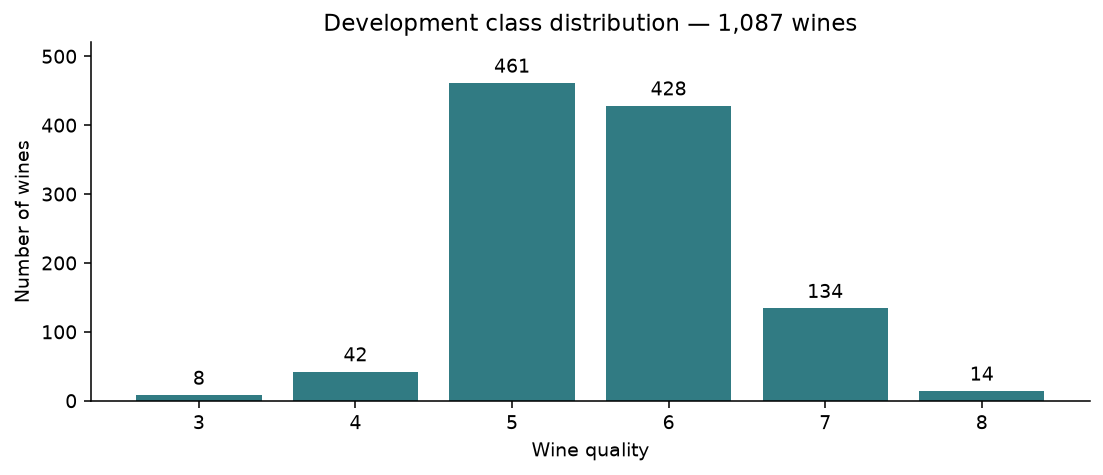

In [4]:
distribution = pd.read_csv(TABLES / 'eda_development_class_distribution.csv')
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(distribution['quality'].astype(str), distribution['count'], color='#317b83')
ax.bar_label(bars, padding=3)
ax.set(
    title='Development class distribution — 1,087 wines',
    xlabel='Wine quality', ylabel='Number of wines', ylim=(0, 520)
)
display_figure(fig)

Higher grades tend to have more alcohol and sulphates and less volatile acidity, although the groups overlap. The next plot uses the saved development medians and interquartile ranges. These ranges describe the wines within each grade; they are not confidence intervals, and the two extreme grades have very small samples.

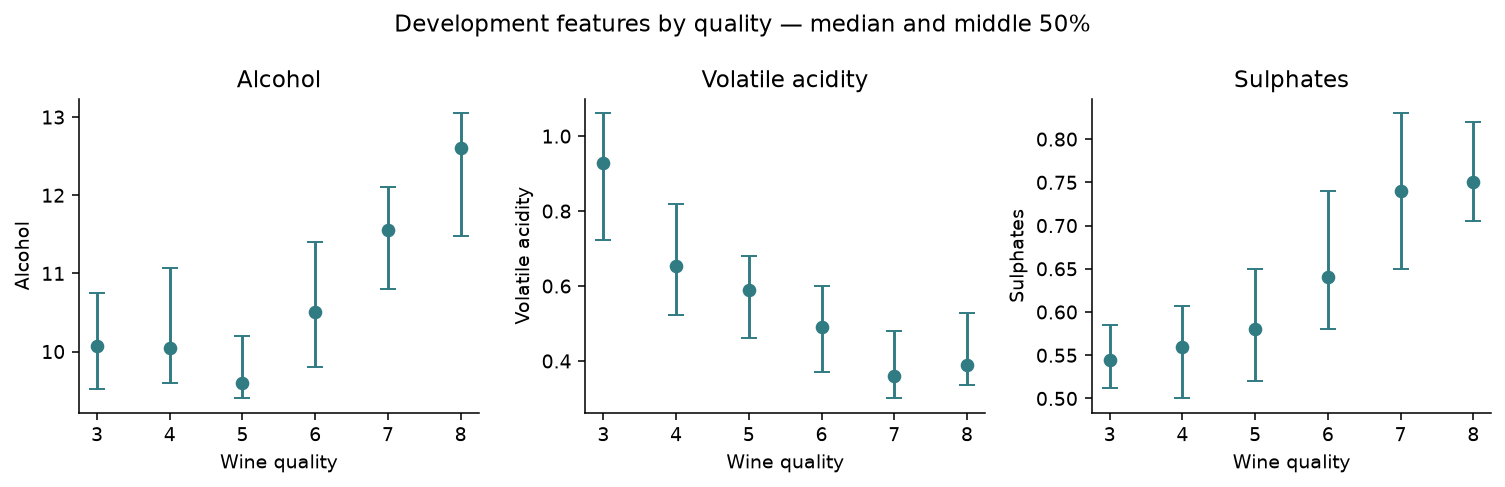

In [5]:
grouped_summary = pd.read_csv(TABLES / 'eda_development_grouped_summary.csv')
plot_features = ['alcohol', 'volatile acidity', 'sulphates']
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, feature in zip(axes, plot_features):
    summary = grouped_summary.loc[grouped_summary['feature'].eq(feature)].sort_values('quality')
    intervals = np.vstack([
        summary['median'] - summary['q25'],
        summary['q75'] - summary['median']
    ])
    ax.errorbar(
        summary['quality'], summary['median'], yerr=intervals,
        fmt='o', capsize=4, color='#317b83'
    )
    ax.set(title=feature.capitalize(), xlabel='Wine quality', ylabel=feature.capitalize())
    ax.set_xticks(CLASSES)
fig.suptitle('Development features by quality — median and middle 50%')
display_figure(fig)

Several predictors share information. Fixed acidity and pH are strongly inversely related, while free and total sulfur dioxide are positively related. The final model retains all eleven predictors, but these correlations matter when interpreting its coefficients: each coefficient describes a variable alongside the other predictors.

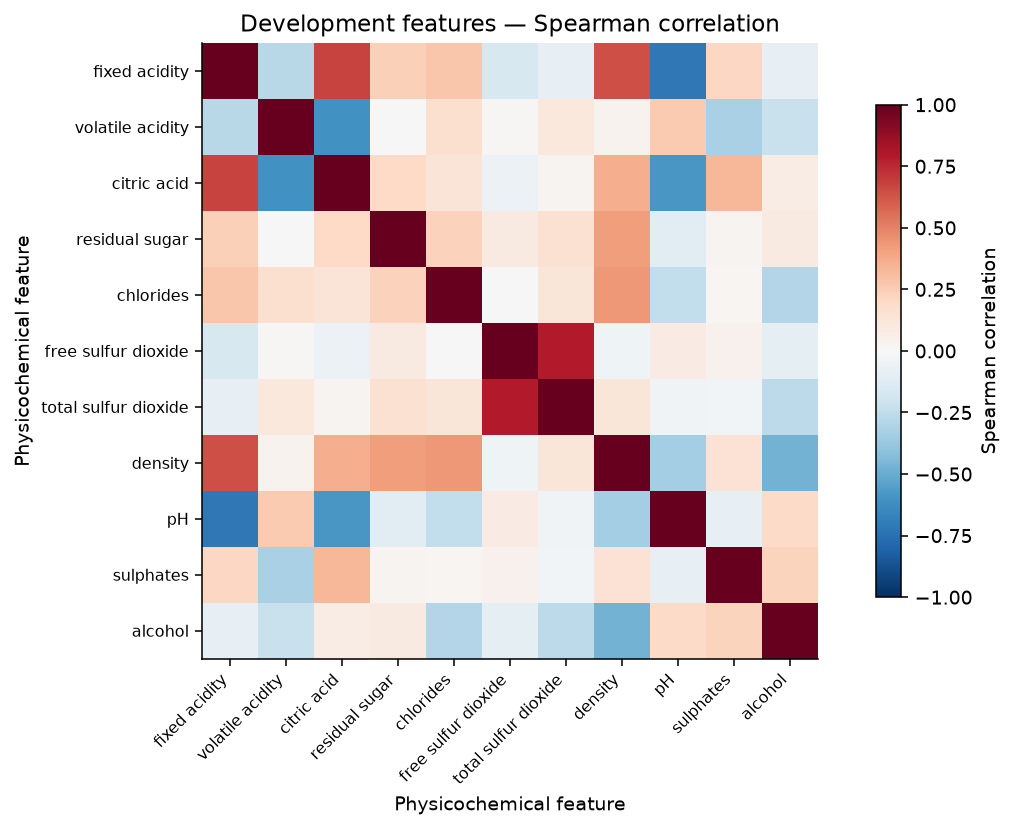

In [6]:
correlation = pd.read_csv(TABLES / 'eda_development_spearman_correlation.csv').set_index('feature')
correlation = correlation.loc[FEATURES, FEATURES]
fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
ax.set(
    title='Development features — Spearman correlation',
    xlabel='Physicochemical feature', ylabel='Physicochemical feature'
)
fig.colorbar(image, ax=ax, label='Spearman correlation', shrink=0.8)
display_figure(fig)

## Evaluation Strategy

**Macro F1** averages the six class F1 values equally. It prevents the many grade-5 and grade-6 wines from dominating model selection. It is different from weighted F1. Balanced Accuracy measures average class recall; QWK, MAE and ±1 accuracy also account for the ordered grades. Macro PR-AUC is reported as mean one-vs-rest average precision.

Version 1 evaluated the original test set once after model selection. **Version 2 used development data only**, without using that test result to choose algorithms, features, weights, thresholds or ensembles. Version 2 scores are therefore development-CV estimates, not new test scores.

The validation-design comparison covered 4- and 5-fold stratified CV, with and without ten repeats. Four folds retain two grade-3 wines in each validation fold; five folds can leave only one. **Four folds × ten repeats** offered a more useful balance between training size and minority representation, even though it did not have the highest diagnostic score. Ten-fold CV was unsuitable for these tiny classes.

Within each outer training split, **3-fold stratified inner CV** selected hyperparameters and imbalance settings using Macro F1. Scaling, learned transformations, class-frequency weights and resampling stayed inside the appropriate training folds. Validation folds contained genuine wines only. Regression cutpoints and class-score multipliers were also selected using training/inner-CV predictions, never outer validation labels.

The table is the earlier validation-design comparison for LDA + SMOTE. Fold SD uses `ddof=0` and describes split variability; overlapping folds do not provide independent confidence intervals.

In [7]:
stability = pd.read_csv(V2 / 'cv_stability_20261012/cv_stability_comparison.csv')
cv_summary = stability.loc[stability['baseline'].eq('lda__smote'), [
    'strategy', 'train_size_min', 'min_class_support',
    'macro_f1_mean', 'macro_f1_std', 'balanced_accuracy_mean', 'quadratic_weighted_kappa_mean'
]].rename(columns={
    'strategy': 'CV design', 'train_size_min': 'Min. training wines',
    'min_class_support': 'Min. class support per validation fold',
    'macro_f1_mean': 'Macro F1', 'macro_f1_std': 'Macro F1 Std',
    'balanced_accuracy_mean': 'Balanced Accuracy', 'quadratic_weighted_kappa_mean': 'QWK'
}).set_index('CV design')
cv_summary = cv_summary.rename(index={
    'SKF_4': '4 folds', 'SKF_5': '5 folds',
    'RSKF_4x10': '4 folds × 10 repeats', 'RSKF_5x10': '5 folds × 10 repeats'
})
display(cv_summary.round(3))

,Min. training wines,Min. class support per validation fold,Macro F1,Macro F1 Std,Balanced Accuracy,QWK
CV design,,,,,,
4 folds,815,2,0.354,0.048,0.365,0.527
5 folds,869,1,0.367,0.036,0.399,0.531
4 folds × 10 repeats,815,2,0.363,0.053,0.392,0.522
5 folds × 10 repeats,869,1,0.370,0.068,0.405,0.526


## Baseline Model Comparison

Version 1 compared fourteen classifiers, including a dummy control. The table shows the leading five and the dummy model from the original **five-fold development CV**. These early results helped form the shortlist; they should not be directly ranked against the later repeated nested-CV results.

A weak initial result did not rule out an entire model family. SVM, boosting and tree ensembles were revisited with controlled tuning and imbalance-aware settings in Version 2.

In [8]:
preliminary = pd.read_csv(TABLES / 'preliminary_model_comparison.csv')
baselines = pd.concat([
    preliminary.head(5), preliminary.loc[preliminary['model_name'].eq('dummy')]
]).drop_duplicates('model_name')
baseline_summary = baselines.loc[:, [
    'display_name', 'macro_f1_mean', 'macro_f1_std',
    'balanced_accuracy_mean', 'quadratic_weighted_kappa_mean'
]].rename(columns={
    'display_name': 'Model', 'macro_f1_mean': 'Macro F1', 'macro_f1_std': 'Macro F1 Std',
    'balanced_accuracy_mean': 'Balanced Accuracy', 'quadratic_weighted_kappa_mean': 'QWK'
}).set_index('Model')
display(baseline_summary.round(3))

,Macro F1,Macro F1 Std,Balanced Accuracy,QWK
Model,,,,
Gaussian naive Bayes,0.322,0.046,0.340,0.483
Linear discriminant analysis,0.316,0.056,0.315,0.525
Logistic regression,0.296,0.042,0.291,0.500
Gradient boosting,0.284,0.012,0.285,0.515
Random forest,0.283,0.018,0.285,0.521
Dummy,0.099,0.000,0.167,0.000


## Model Tuning and Class Imbalance

The searches covered linear models, RBF SVM, Random Forest, Extra Trees, XGBoost, CatBoost and LightGBM. The comparisons included unweighted models, frequency-based weighting and moderated custom weights. Search ranges were kept conservative for the small dataset, particularly tree depth. Tuned boosting models did not outperform the LDA procedures on Macro F1.

Resampling comparisons included no resampling, random oversampling, capped SMOTE, restricted BorderlineSMOTE and protected SMOTE–Tomek. ADASYN and SMOTEENN were not pursued because the tiny classes made their local allocation or cleaning difficult to justify. All resampling took place within training folds to avoid leakage.

The selected approach uses gentle capped SMOTE (`k=1`) followed by Tomek cleaning restricted to grades 5 and 6. Its final development fit added **65 synthetic rows** and removed **163 majority-class rows**, leaving **989 training rows** while retaining genuine minority wines. SMOTE can improve balance, but it cannot create new independent wines.

**Feature engineering.** The study also tested two small feature sets with LDA and ordered-threshold logistic classification. The augmented set added these six terms to the original predictors:

| Derived feature | Formula evaluated |
|---|---|
| Bound sulfur dioxide | total sulfur dioxide − free sulfur dioxide |
| Free sulfur fraction | free sulfur dioxide / total sulfur dioxide |
| Alcohol–density interaction | alcohol × (density − 1) |
| Volatile/fixed acidity ratio | volatile acidity / fixed acidity |
| Citric/fixed acidity ratio | citric acid / fixed acidity |
| Acidity–pH interaction | fixed acidity × 10^(3 − pH) |

The compact set had **14 predictors**: it replaced free and total sulfur dioxide with bound sulfur and free fraction, added the alcohol–density, volatile/fixed acidity and acidity–pH terms, and omitted the citric/fixed ratio. In the completed compact runs, `log1p` was applied to residual sugar, chlorides, sulphates and bound sulfur dioxide. Eligibility depended only on nonnegative training values and training skewness above 1. These ratios and interactions are numerical chemistry proxies, not chemical mole fractions.

The [saved experiment notes](../tables/deadline_optimization_summary.md#compact-feature-definitions) give the formulas, and the [training records](../tables/version_2/deadline_20261015/training_audits.json) confirm that both sets ran for both models across four screening folds. Neither improved Macro F1 consistently, so the final model retains the original eleven predictors.

Modest class-score multipliers and equal/2:1 soft voting were also screened. None met the planned requirement of a 0.01 Macro F1 gain with improvement in at least three of four folds. No ensemble was retained. These screening results were not substituted for the repeated-CV estimates.

## Ordinal / Regression Alternatives

Because quality is ordered, the study compared cumulative-link logistic classification and five ordered binary questions, from `quality > 3` to `quality > 7`. The binary outputs were made monotone and converted into probabilities for the six grades. These are true ordinal approaches; ordinary multiclass LDA does not impose that order.

A separate study used regression to predict continuous quality. It compared naive rounding with five ordered cutpoints optimized for Macro F1 using **training/inner-CV predictions only**. Extra Trees was the strongest regression family. Its ordinal error measures were useful, but neither regression nor ordinal classification surpassed the LDA group on Macro F1.

Below, matched rounding uses the same selected regressor as optimized cutpoints. QWK and MAE support the comparison but do not replace the six-class objective. Regression produced no class-ranking scores, so its Macro PR-AUC is unavailable rather than zero.

In [9]:
ordinal_metrics = pd.read_csv(V2 / 'ordinal_20261015/metric_comparison.csv')
regression_metrics = pd.read_csv(V2 / 'regression_ordinal_20261015/metric_comparison.csv')
ordinal_rows = ordinal_metrics.loc[ordinal_metrics['model'].isin(['cumulative_logit', 'ordered_thresholds'])]
regression_rows = regression_metrics.loc[regression_metrics['model'].isin([
    'extra_trees__optimized_thresholds', 'extra_trees__matched_rounding'
])]
ordinal_comparison = pd.concat([ordinal_rows, regression_rows]).pivot(
    index='model', columns='metric', values='mean'
)
ordinal_comparison = ordinal_comparison.rename(index={
    'cumulative_logit': 'Cumulative-link logistic',
    'ordered_thresholds': 'Ordered-threshold logistic',
    'extra_trees__optimized_thresholds': 'Extra Trees regression + cutpoints',
    'extra_trees__matched_rounding': 'Extra Trees regression + rounding'
})
ordinal_display = ordinal_comparison.loc[:, [
    'macro_f1', 'balanced_accuracy', 'quadratic_weighted_kappa', 'mae', 'within_one_accuracy'
]].rename(columns={
    'macro_f1': 'Macro F1', 'balanced_accuracy': 'Balanced Accuracy',
    'quadratic_weighted_kappa': 'QWK', 'mae': 'MAE', 'within_one_accuracy': '±1 Accuracy'
})
ordinal_display.index.name = 'Model'
ordinal_display.columns.name = None
display(ordinal_display.round(3))

,Macro F1,Balanced Accuracy,QWK,MAE,±1 Accuracy
Model,,,,,
Cumulative-link logistic,0.313,0.317,0.522,0.506,0.952
Extra Trees regression + rounding,0.267,0.269,0.505,0.428,0.966
Extra Trees regression + cutpoints,0.340,0.370,0.580,0.499,0.951
Ordered-threshold logistic,0.349,0.365,0.524,0.518,0.936


## Final Model and Results

The selected model is **LDA (`solver="lsqr"`, `shrinkage=0.8`) with StandardScaler, gentle capped SMOTE and protected Tomek cleaning**. It had the highest recorded mean Macro F1, with slightly lower fold variability and higher Balanced Accuracy than capped SMOTE alone. The two LDA variants are a **practical tie**; standard SMOTE has slightly better QWK, MAE and ±1 accuracy. More complex models did not establish a stronger alternative.

The final model uses all eleven original predictors, with no custom class weights, engineered features, optimized cutpoints, score multipliers or ensemble. Its gentle SMOTE setting and `k=1` were selected from the existing inner-CV records.

The comparison below shows seven representative approaches. All rows are **Version 2 development estimates from 4 folds × 10 repeats**, with model/imbalance choices made in inner CV. The score for the selected approach describes that selection procedure, which could choose different sampler settings in different folds; it is not a separately unseen estimate of the exact final fixed recipe. Comparing many model families on the same development data can also make the selected estimate optimistic.

In [10]:
# Read the full-precision saved table; select columns without recalculating results.
leaderboard = pd.read_csv(TABLES / 'final_leaderboard.csv', float_precision='round_trip')
representative_models = [
    'LDA + protected SMOTE–Tomek', 'LDA + capped SMOTE',
    'Ordered-threshold logistic', 'Extra Trees regression + cutpoints',
    'Random Forest — balanced subsample', 'CatBoost — SqrtBalanced',
    'RBF SVM — tuned custom weights'
]
comparison_columns = [
    'Model', 'Macro F1', 'Macro F1 Std', 'Balanced Accuracy', 'QWK', 'Accuracy', '±1 Accuracy'
]
comparison = leaderboard.loc[
    leaderboard['Model'].isin(representative_models), comparison_columns
].copy()
comparison = comparison.set_index('Model').rename(index={
    'LDA + protected SMOTE–Tomek': 'LDA + protected SMOTE–Tomek (selected)'
})
display(comparison.round(3))
selected_result = leaderboard.set_index('Model').loc['LDA + protected SMOTE–Tomek']

,Macro F1,Macro F1 Std,Balanced Accuracy,QWK,Accuracy,±1 Accuracy
Model,,,,,,
LDA + protected SMOTE–Tomek (selected),0.367,0.055,0.391,0.527,0.540,0.931
LDA + capped SMOTE,0.367,0.056,0.385,0.529,0.549,0.936
Ordered-threshold logistic,0.349,0.062,0.365,0.524,0.551,0.936
Extra Trees regression + cutpoints,0.340,0.053,0.370,0.580,0.552,0.951
Random Forest — balanced subsample,0.335,0.045,0.377,0.551,0.536,0.932
CatBoost — SqrtBalanced,0.326,0.050,0.328,0.553,0.578,0.953
RBF SVM — tuned custom weights,0.310,0.038,0.329,0.493,0.543,0.927


The [complete leaderboard](../tables/final_leaderboard.csv) retains all ten models, detailed metrics and runtime information at full precision.

The selected procedure achieved **Macro F1 0.367**, with fold SD **0.055** and a fold range of **0.263–0.475**. Balanced Accuracy was **0.391**, QWK **0.527**, Macro PR-AUC **0.392**, Accuracy **0.540**, MAE **0.536** and ±1 accuracy **0.931**. A Macro F1 of 0.50 was not achieved.

Performance is uneven across grades. The table shows mean-fold precision, recall and F1, alongside pooled out-of-fold (OOF) F1. Averaging the six mean-fold F1 values gives the reported Macro F1. Pooling predictions first gives **0.365**, a slightly different aggregation of the same results.

In [11]:
class_results = pd.read_csv(FINAL_RESULTS / 'fold_mean_per_class.csv', float_precision='round_trip')
oof_counts = pd.read_csv(TABLES / 'submission/champion_class_reconstruction.csv', float_precision='round_trip')
per_class = class_results.loc[:, ['quality', 'precision', 'recall', 'f1-score']].rename(columns={
    'quality': 'Quality', 'precision': 'Mean precision', 'recall': 'Mean recall', 'f1-score': 'Mean F1'
})
per_class = per_class.merge(
    oof_counts.loc[:, ['Quality', 'Pooled OOF F1', 'True OOF count', 'Predicted OOF count']],
    on='Quality', validate='one_to_one'
).set_index('Quality')
display(per_class.round(3))
np.testing.assert_allclose(per_class['Mean F1'].mean(), selected_result['Macro F1'], rtol=0, atol=1e-12)

,Mean precision,Mean recall,Mean F1,Pooled OOF F1,True OOF count,Predicted OOF count
Quality,,,,,,
3,0.340,0.412,0.337,0.325,80,123
4,0.166,0.148,0.148,0.155,420,379
5,0.645,0.708,0.674,0.674,4610,5073
6,0.532,0.415,0.465,0.466,4280,3357
7,0.416,0.531,0.464,0.464,1340,1731
8,0.105,0.133,0.111,0.104,140,207


The confusion matrix contains **10,870 OOF prediction records from 1,087 unique wines**: each wine appears once per repeat. It does not represent 10,870 independent observations. Most correct predictions are in the common middle grades; qualities 4 and 8 remain particularly difficult.

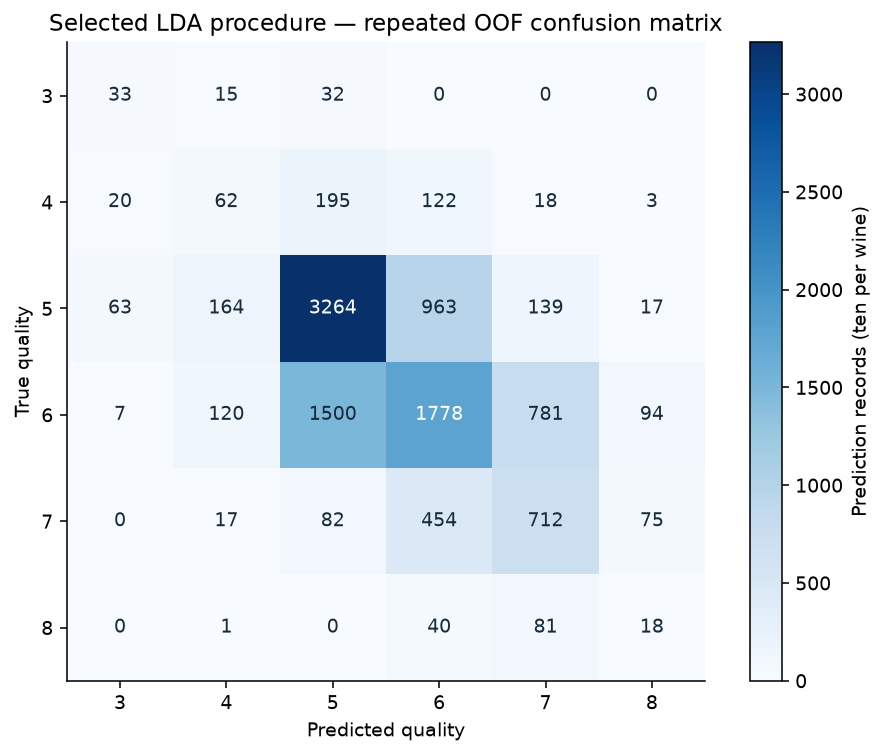

In [12]:
oof = pd.read_csv(
    V2 / 'additional_imbalance_20261014/outer_oof_predictions.csv',
    usecols=['model', 'source_row_index', 'actual_quality', 'predicted_quality']
)
selected_oof = oof.loc[oof['model'].eq('lda__smote_tomek_protected')].copy()
confusion_counts = confusion_matrix(selected_oof['actual_quality'], selected_oof['predicted_quality'], labels=CLASSES)
pooled_macro_f1 = f1_score(
    selected_oof['actual_quality'], selected_oof['predicted_quality'],
    labels=CLASSES, average='macro', zero_division=0
)
np.testing.assert_array_equal(confusion_counts.sum(axis=1), per_class['True OOF count'])
np.testing.assert_array_equal(confusion_counts.sum(axis=0), per_class['Predicted OOF count'])
np.testing.assert_allclose(pooled_macro_f1, per_class['Pooled OOF F1'].mean(), rtol=0, atol=1e-12)

fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(confusion_counts, cmap='Blues')
for row in range(len(CLASSES)):
    for column in range(len(CLASSES)):
        color = 'white' if confusion_counts[row, column] > confusion_counts.max() / 2 else '#172b3a'
        ax.text(column, row, str(confusion_counts[row, column]), ha='center', va='center', color=color)
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(
    title='Selected LDA procedure — repeated OOF confusion matrix',
    xlabel='Predicted quality', ylabel='True quality'
)
fig.colorbar(image, ax=ax, label='Prediction records (ten per wine)')
display_figure(fig)

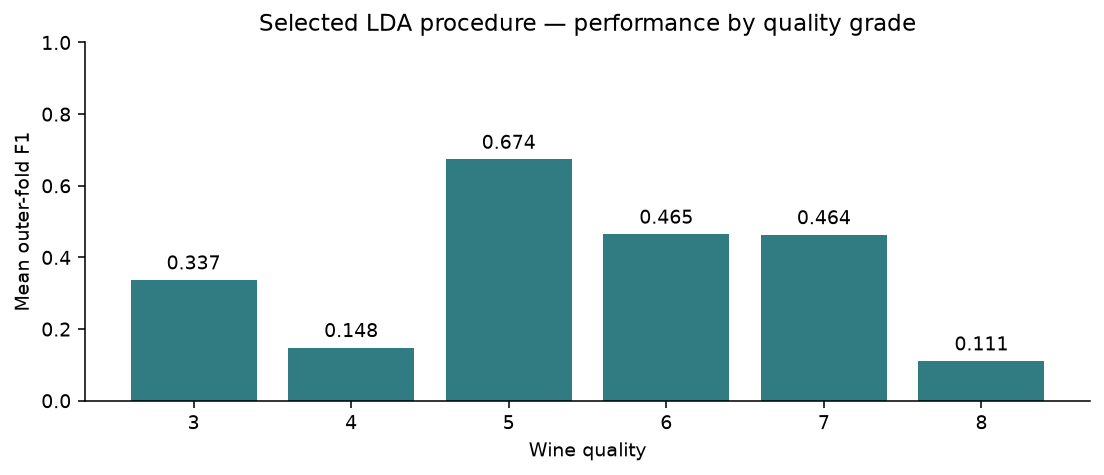

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(per_class.index.astype(str), per_class['Mean F1'], color='#317b83')
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(
    title='Selected LDA procedure — performance by quality grade',
    xlabel='Wine quality', ylabel='Mean outer-fold F1', ylim=(0, 1)
)
display_figure(fig)

**Version 1 test result.** The original LDA + SMOTE model was evaluated once on the 272-wine test set after its selection. Its saved result is shown separately below. It belongs to Version 1 and was not used to select the Version 2 model. Version 2 has no new independent test result.

In [14]:
version1_result = pd.read_csv(TABLES / 'final_test_metrics.csv', float_precision='round_trip')
metric_names = {
    'macro_f1': 'Macro F1', 'balanced_accuracy': 'Balanced Accuracy',
    'quadratic_weighted_kappa': 'QWK', 'macro_average_precision_ovr': 'Macro PR-AUC',
    'accuracy': 'Accuracy', 'mae': 'MAE', 'within_one_accuracy': '±1 Accuracy'
}
version1_display = version1_result.loc[:, list(metric_names)].rename(columns=metric_names)
version1_display.index = ['Version 1 test']
display(version1_display.round(3))

,Macro F1,Balanced Accuracy,QWK,Macro PR-AUC,Accuracy,MAE,±1 Accuracy
Version 1 test,0.359,0.402,0.561,0.359,0.581,0.485,0.941


## Model Interpretation: LDA Coefficients

Standardized LDA coefficients describe how each predictor contributes to a class score when the other predictors are held fixed. The heatmap subtracts the across-class mean coefficient, so positive values favor a class relative to the average class score. This centering preserves predictions and makes the class contrasts easier to see.

The coefficients are associations, not causal effects; correlated predictors, resampling and the small extreme classes limit their interpretation. The model combines all predictors, so these conditional coefficients need not follow every marginal EDA pattern. They are not changes in probability.

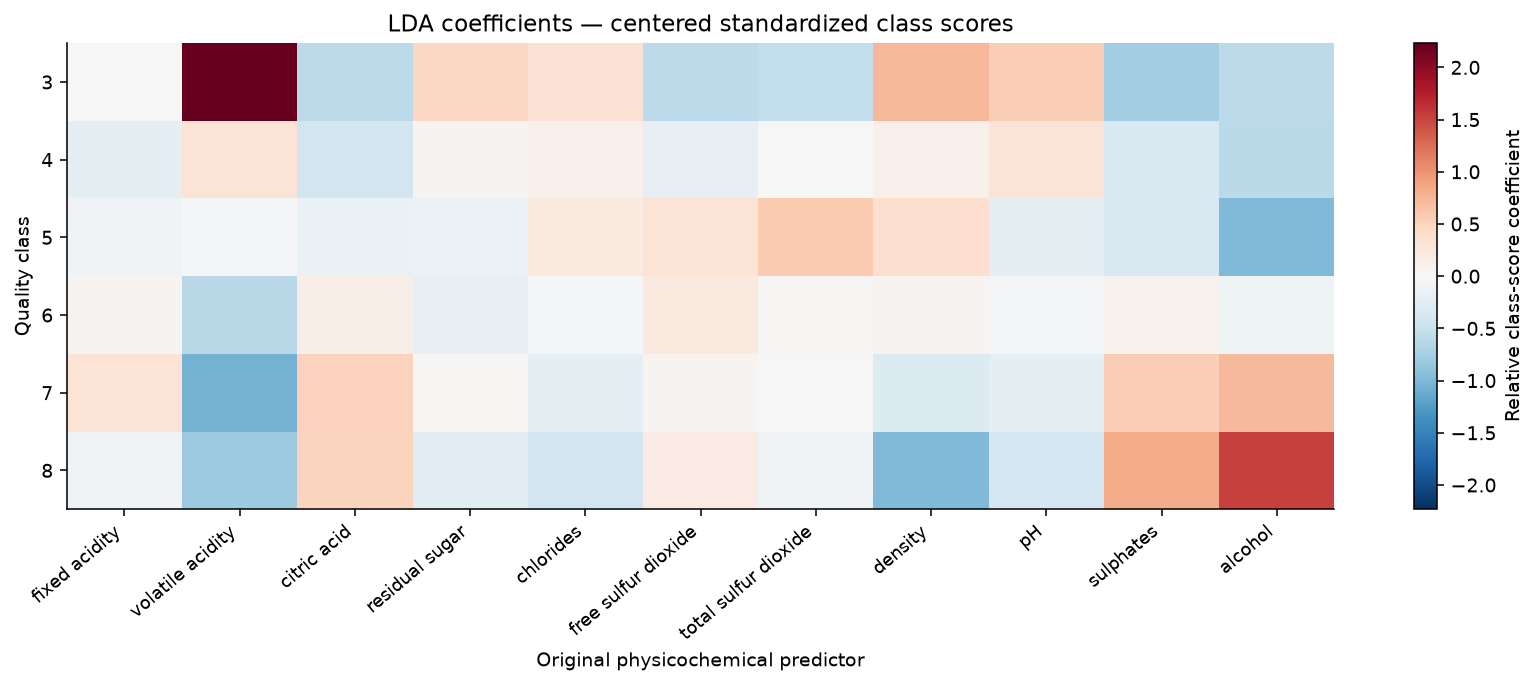

In [15]:
final_model = joblib.load(MODEL_PATH)
model_metadata = json.loads(METADATA_PATH.read_text())
np.testing.assert_array_equal(final_model.feature_names_in_, FEATURES)
np.testing.assert_array_equal(final_model.classes_, CLASSES)
np.testing.assert_allclose(
    selected_result['Macro F1'], model_metadata['validation_metrics']['macro_f1']['mean'],
    rtol=0, atol=1e-12
)

lda = final_model.named_steps['classifier']
centered_coefficients = lda.coef_ - lda.coef_.mean(axis=0, keepdims=True)
fig, ax = plt.subplots(figsize=(12, 5))
limit = np.abs(centered_coefficients).max()
image = ax.imshow(centered_coefficients, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(
    title='LDA coefficients — centered standardized class scores',
    xlabel='Original physicochemical predictor', ylabel='Quality class'
)
fig.colorbar(image, ax=ax, label='Relative class-score coefficient')
display_figure(fig)

## Limitations

- **Rare-class recognition is weak.** Mean F1 is only 0.148 for quality 4 and 0.111 for quality 8. Pooled quality-8 precision is 0.087 and recall 0.129, so many predictions of this extreme grade are wrong.
- **Validation reuses a small dataset.** Repeated folds overlap, and many models were compared. Nested tuning reduces leakage but does not remove optimism from choosing among studies. The exact final fixed recipe has no separately unseen validation estimate.
- **Ordinal closeness is not exact classification.** QWK and ±1 accuracy can look reasonable while rare-grade prediction remains poor.
- **Resampling has limits.** Synthetic wines do not increase independent sample size, and cleaning can remove useful majority-class boundaries. The two leading LDA variants are practically tied.
- **Generalization is uncertain.** No wine/batch identifiers, external validation or probability-calibration results are available. Removing exact duplicates does not rule out dependence between related wines. The old test result cannot serve as a fresh Version 2 evaluation.

A three-class Low/Medium/High formulation would be easier because adjacent quality grades are merged, but this project retained all six original quality values to preserve target granularity. Scores from the two tasks are not directly comparable.

## Conclusion

LDA with conservative SMOTE and protected Tomek cleaning gave the strongest recorded Macro F1, **0.367 with fold SD 0.055**, while effectively tying capped SMOTE alone. Weighting, more complex classifiers, ordinal/regression alternatives and the limited feature/decision-rule experiments did not establish a stronger replacement. The final model retains the original eleven predictors and the selected LDA configuration.

The main limitation is the small number of genuine rare-grade wines. The model captures some quality-related structure, but its weak minority performance means the result should be read as a modest development-CV estimate rather than a reliable grading system.

## Reproducibility Notes

- Random state: **42**. Historical development/test membership remains in `data/split_manifest.json`.
- Preprocessing and resampling stayed inside training folds; tuning and decision rules used inner CV. The original test set was not reused for Version 2 selection.
- The fitted scaler and LDA are saved in `models/final/wine_quality_classifier_v2.joblib`, with parameters and environment information in the adjacent metadata file. Resampling is a training step, not an inference step.
- Use the pinned `requirements.txt`, start the kernel in the project root or `notebook/`, and select **Restart Kernel and Run All**. The report reads saved results; CSV precision and saved models are unchanged.

**Prediction example.** The two handwritten wines below demonstrate model loading and inference. They have no known quality labels, so they are not an accuracy test. The probability columns follow classes 3–8 and should not be interpreted as calibrated confidence.

For standalone CSV inference from the project root, run `python predict.py wine_inputs.csv --output wine_predictions.csv`. Supply the eleven feature columns in metadata order, without the target. Use `python verify_notebook_replay.py --cwd notebook` for the guarded report check.

In [16]:
def predict_quality(model, wines):
    """Predict from the eleven numeric inputs in the expected column order."""
    if not isinstance(wines, pd.DataFrame) or wines.empty or list(wines.columns) != FEATURES:
        raise ValueError('Supply a nonempty DataFrame with the eleven feature columns in order.')
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in wines.dtypes):
        raise ValueError('Feature values must be numeric.')
    if not np.isfinite(wines.to_numpy(dtype=float)).all():
        raise ValueError('Feature values must be finite and complete.')

    if (wines < 0).any().any() or (wines['density'] <= 0).any():
        raise ValueError('Measurements must be nonnegative and density must be positive.')
    if not wines['pH'].between(0, 14).all() or not wines['alcohol'].between(0, 100).all():
        raise ValueError('Use pH on the 0–14 scale and alcohol as percent by volume.')

    predictions = model.predict(wines)
    probabilities = model.predict_proba(wines)
    result = pd.DataFrame({'Predicted quality': predictions}, index=wines.index)
    for column, quality in enumerate(model.classes_):
        result[f'P(quality={quality})'] = probabilities[:, column]
    return result

In [17]:
example_wines = pd.DataFrame({
    'fixed acidity': [7.6, 9.1], 'volatile acidity': [0.51, 0.34],
    'citric acid': [0.18, 0.43], 'residual sugar': [2.3, 2.1],
    'chlorides': [0.076, 0.080], 'free sulfur dioxide': [17., 13.],
    'total sulfur dioxide': [48., 39.], 'density': [0.9964, 0.9971],
    'pH': [3.30, 3.19], 'sulphates': [0.67, 0.74], 'alcohol': [10.6, 11.4]
}, index=pd.Index(['illustrative_A', 'illustrative_B'], name='Wine'))
example_predictions = predict_quality(final_model, example_wines)
display(example_predictions.round(3))

,Predicted quality,P(quality=3),P(quality=4),P(quality=5),P(quality=6),P(quality=7),P(quality=8)
Wine,,,,,,,
illustrative_A,6,0.000,0.051,0.361,0.511,0.074,0.003
illustrative_B,6,0.000,0.004,0.058,0.474,0.444,0.019
